# **CS-746 Perspectives on Data Science**

**Project :** Credit Card Fraud Detection Using Machine Learning


In [1]:
# Importing these libraries for data loading,cleaning and manipulation
import pandas as pd
import numpy as np

# Importing these libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#uploading the credit_card.csv dataset downloaded from kaggle
from google.colab import files
uploaded = files.upload()

Saving creditcard.csv to creditcard.csv


In [3]:
# Displaying first twenty five observations of the dataset
df = pd.read_csv('creditcard.csv')
print("Dataset loaded successfully.")
df.head(25)

Dataset loaded successfully.


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
5,2.0,-0.425966,0.960523,1.141109,-0.168252,0.420987,-0.029728,0.476201,0.260314,-0.568671,...,-0.208254,-0.559825,-0.026398,-0.371427,-0.232794,0.105915,0.253844,0.081080,3.67,0
6,4.0,1.229658,0.141004,0.045371,1.202613,0.191881,0.272708,-0.005159,0.081213,0.464960,...,-0.167716,-0.270710,-0.154104,-0.780055,0.750137,-0.257237,0.034507,0.005168,4.99,0
7,7.0,-0.644269,1.417964,1.074380,-0.492199,0.948934,0.428118,1.120631,-3.807864,0.615375,...,1.943465,-1.015455,0.057504,-0.649709,-0.415267,-0.051634,-1.206921,-1.085339,40.80,0
8,7.0,-0.894286,0.286157,-0.113192,-0.271526,2.669599,3.721818,0.370145,0.851084,-0.392048,...,-0.073425,-0.268092,-0.204233,1.011592,0.373205,-0.384157,0.011747,0.142404,93.20,0
9,9.0,-0.338262,1.119593,1.044367,-0.222187,0.499361,-0.246761,0.651583,0.069539,-0.736727,...,-0.246914,-0.633753,-0.120794,-0.385050,-0.069733,0.094199,0.246219,0.083076,3.68,0


In [4]:
# Displaying the  dataset rows and columns
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Displaying the column names of the dataset
print("\nDataset column names n:","\n",df.columns.tolist())

# Displaying the data types of the dataset
print("\nDataset Datatypes:")
print(df.dtypes)

Number of rows: 284807
Number of columns: 31

Dataset column names n: 
 ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Dataset Datatypes:
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object


**Dataset Structure**

loaded  the Credit card Fraud dataset, it contains 284,807 transaction records(rows) and 31 columns. The dataset has Time, Amount, 28 anonymized features (V1 to V28), and one target column that is Class. From the data type analysis, I observed that 30 columns have the float data type and the Class column has the integer data type. This analysis helped me understand the dataset structure.

In [5]:
#checking for  the missing in each column of the dataset
missing_val = df.isnull().sum()
print("Missing values in each column:","\n",missing_val)
print("\nTotal missing values:", missing_val.sum())

Missing values in each column: 
 Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

Total missing values: 0


In [6]:
# Identifying duplicate records in the Dataset
duplicate_data = df[df.duplicated()]
print("Total duplicate records:", len(duplicate_data))

# Checking duplicate records based on transaction class of the Dataset
print("\nDuplicate records by transaction class:")
print(duplicate_data['Class'].value_counts())

Total duplicate records: 1081

Duplicate records by transaction class:
Class
0    1062
1      19
Name: count, dtype: int64


In [7]:
# Counting  transactions based on class column
class_count = df['Class'].value_counts()
print("Transaction class distribution:","\n",class_count)

# Calculating percentages based on class column
class_percent = df['Class'].value_counts(normalize=True) * 100
print("\nPercentage of Class Distribution:","\n",class_percent)

Transaction class distribution: 
 Class
0    284315
1       492
Name: count, dtype: int64

Percentage of Class Distribution: 
 Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


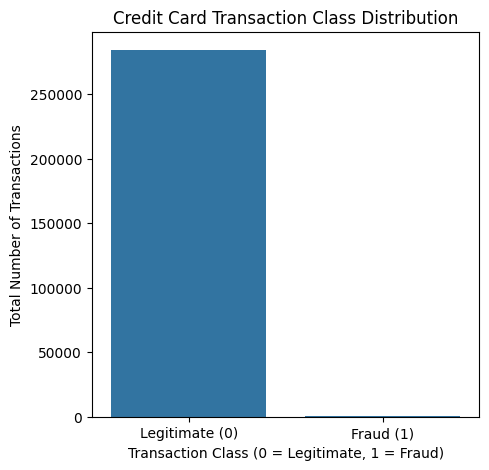

In [8]:
# Visualizing transactions based on class distribution
plt.figure(figsize=(5, 5))
sns.countplot(data=df, x='Class')

#assigning titles to the visualization graph of credit card transaction class
plt.title('Credit Card Transaction Class Distribution')
plt.xlabel('Transaction Class (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Total Number of Transactions')
plt.xticks([0, 1], ['Legitimate (0)', 'Fraud (1)'])
plt.show()

**Missing Values, Duplicate Records and Class Distribution Analysis**

After checking the dataset, I found that there are no missing values across the 31 columns. But there are 1081 duplicate records, including 1062 legitimate transactions (Class 0) and 19 fraudulent transactions (Class 1).

The class distribution analysis showed that the dataset contains 284315 legitimate transactions (Class 0), nearly the percentage is (%) 99.83, and 492 fraudulent transactions (Class 1) with percentage(%) of 0.17. The bar chart shows the significant difference between the two classes. This analysis helped me understand the data quality and the imbalanceness of the class that needs to be addressed during data preprocessing.

In [9]:
# Displaying mean,count,stadard deviation,min,max and perecentage analysis of the dataset
print("Descriptive Statistical Analysis:")
df.describe()

Descriptive Statistical Analysis:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


**Descriptive Analysis**

After running the descriptive statistical analysis, I got a summary of all the numerical features, including their count, mean, standard deviation, minimum, maximum, and quartile values. I observed that the features have different value ranges and variations. This helped me get a better understanding of the transaction data and identify the need for feature scaling during preprocessing.

In [10]:
# Performing correlation analysis on the dataset
correlation_matrix = df.corr()
print("Correlation Analysis:")
display(correlation_matrix)

Correlation Analysis:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
Time,1.000000,1.173963e-01,-1.059333e-02,-4.196182e-01,-1.052602e-01,1.730721e-01,-6.301647e-02,8.471437e-02,-3.694943e-02,-8.660434e-03,...,4.473573e-02,1.440591e-01,5.114236e-02,-1.618187e-02,-2.330828e-01,-4.140710e-02,-5.134591e-03,-9.412688e-03,-0.010596,-0.012323
V1,0.117396,1.000000e+00,4.135835e-16,-1.227819e-15,-9.215150e-16,1.812612e-17,-6.506567e-16,-1.005191e-15,-2.433822e-16,-1.513678e-16,...,-2.457409e-16,-4.290944e-16,6.168652e-16,-4.425156e-17,-9.605737e-16,-1.581290e-17,1.198124e-16,2.083082e-15,-0.227709,-0.101347
V2,-0.010593,4.135835e-16,1.000000e+00,3.243764e-16,-1.121065e-15,5.157519e-16,2.787346e-16,2.055934e-16,-5.377041e-17,1.978488e-17,...,-8.480447e-17,1.526333e-16,1.634231e-16,1.247925e-17,-4.478846e-16,2.057310e-16,-4.966953e-16,-5.093836e-16,-0.531409,0.091289
V3,-0.419618,-1.227819e-15,3.243764e-16,1.000000e+00,4.711293e-16,-6.539009e-17,1.627627e-15,4.895305e-16,-1.268779e-15,5.568367e-16,...,5.706192e-17,-1.133902e-15,-4.983035e-16,2.686834e-19,-1.104734e-15,-1.238062e-16,1.045747e-15,9.775546e-16,-0.210880,-0.192961
V4,-0.105260,-9.215150e-16,-1.121065e-15,4.711293e-16,1.000000e+00,-1.719944e-15,-7.491959e-16,-4.104503e-16,5.697192e-16,6.923247e-16,...,-1.949553e-16,-6.276051e-17,9.164206e-17,1.584638e-16,6.070716e-16,-4.247268e-16,3.977061e-17,-2.761403e-18,0.098732,0.133447
V5,0.173072,1.812612e-17,5.157519e-16,-6.539009e-17,-1.719944e-15,1.000000e+00,2.408382e-16,2.715541e-16,7.437229e-16,7.391702e-16,...,-3.920976e-16,1.253751e-16,-8.428683e-18,-1.149255e-15,4.808532e-16,4.319541e-16,6.590482e-16,-5.613951e-18,-0.386356,-0.094974
V6,-0.063016,-6.506567e-16,2.787346e-16,1.627627e-15,-7.491959e-16,2.408382e-16,1.000000e+00,1.191668e-16,-1.104219e-16,4.131207e-16,...,5.833316e-17,-4.705235e-19,1.046712e-16,-1.071589e-15,4.562861e-16,-1.357067e-16,-4.452461e-16,2.594754e-16,0.215981,-0.043643
V7,0.084714,-1.005191e-15,2.055934e-16,4.895305e-16,-4.104503e-16,2.715541e-16,1.191668e-16,1.000000e+00,3.344412e-16,1.122501e-15,...,-2.027779e-16,-8.898922e-16,-4.387401e-16,7.434913e-18,-3.094082e-16,-9.657637e-16,-1.782106e-15,-2.776530e-16,0.397311,-0.187257
V8,-0.036949,-2.433822e-16,-5.377041e-17,-1.268779e-15,5.697192e-16,7.437229e-16,-1.104219e-16,3.344412e-16,1.000000e+00,4.356078e-16,...,3.892798e-16,2.026927e-16,6.377260e-17,-1.047097e-16,-4.653279e-16,-1.727276e-16,1.299943e-16,-6.200930e-16,-0.103079,0.019875
V9,-0.008660,-1.513678e-16,1.978488e-17,5.568367e-16,6.923247e-16,7.391702e-16,4.131207e-16,1.122501e-15,4.356078e-16,1.000000e+00,...,1.936953e-16,-7.071869e-16,-5.214137e-16,-1.430343e-16,6.757763e-16,-7.888853e-16,-6.709655e-17,1.110541e-15,-0.044246,-0.097733


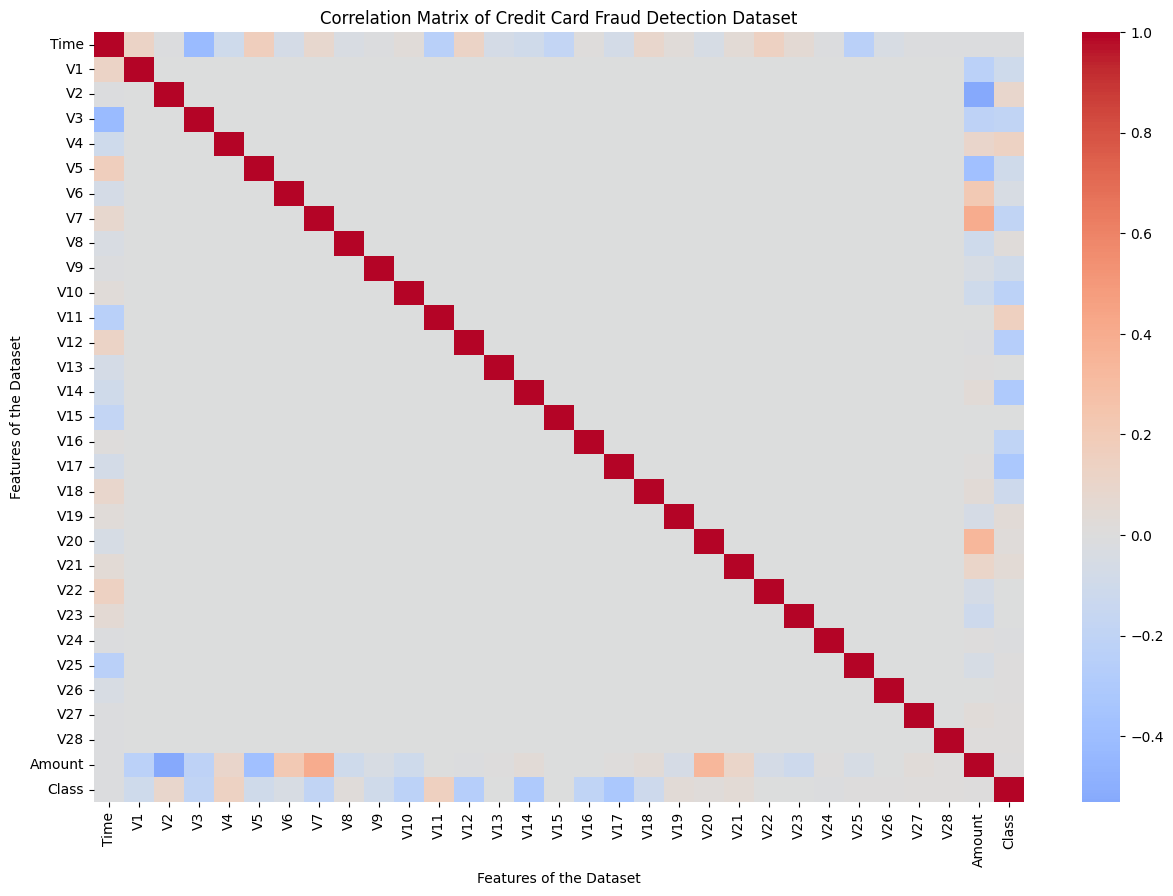

In [11]:
# Visualizing the correlation matrix using a heatmap
plt.figure(figsize=(15, 10))
sns.heatmap(correlation_matrix,cmap='coolwarm',annot=False,center=0)

#assigning titles for the visualization of correlation matrix
plt.title("Correlation Matrix of Credit Card Fraud Detection Dataset")
plt.xlabel("Features of the Dataset")
plt.ylabel("Features of the Dataset")
plt.show()

**Correlation Analysis and Heatmap Visualization**

After performing correlation analysis, I created a correlation matrix to understand the relationships between the numerical features. I also used a heatmap to visualize these relationships and observed that most of the anonymized PCA features have very low correlations with each other. This helped me get a better understanding of how the different features are related to one another.

In [12]:
# Removing duplicate records from the dataset
df_clean = df.drop_duplicates().copy()

print("Dataset shape before removing duplicates:", df.shape)
print("Dataset shape after removing duplicates:", df_clean.shape)
print("\nRemaining duplicate records:", df_clean.duplicated().sum())

Dataset shape before removing duplicates: (284807, 31)
Dataset shape after removing duplicates: (283726, 31)

Remaining duplicate records: 0


In [13]:
# Separating independent and dependent variables from the dataset
X = df_clean.drop('Class', axis=1)
Y = df_clean['Class']

print("Independent features shape:", X.shape)
print("Target variable shape:", Y.shape)

Independent features shape: (283726, 30)
Target variable shape: (283726,)


In [14]:
# importing training and testing sets from sklearn
from sklearn.model_selection import train_test_split

# Splitting the dataset into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size=0.20,random_state=42,stratify=Y)
print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", Y_train.shape)
print("Testing target shape:", Y_test.shape)

Training features shape: (226980, 30)
Testing features shape: (56746, 30)
Training target shape: (226980,)
Testing target shape: (56746,)


In [15]:
# Importing StandardScaler from sklearn for feature scaling
from sklearn.preprocessing import StandardScaler

# Applying feature Scaling the training & testing data
scaler = StandardScaler()
X_train[['Time', 'Amount']] = scaler.fit_transform(X_train[['Time', 'Amount']])
X_test[['Time', 'Amount']] = scaler.transform(X_test[['Time', 'Amount']])

**Data Cleaning, Feature Separation, Train-Test Split and Feature Scaling**

After removing the duplicate records, the dataset got reduced from 284807 to 283726 records, with no remaining duplicate rows. I separated the dataset into 30 independent features (X) and one target variable (Y), that is the Class column.

divided the Dataset into 226980 training records (80%) and 56746 testing records (20%). Stratified splitting maintained the class distribution in both sets. then I applied StandardScaler to the Time and Amount features by fitting the scaler on the training data and applying the same scaling parameters to the testing data.

In [16]:
# Displaying the class distribution before applying SMOTE
print("Class Distribution Before Applying SMOTE:")
print("Class 0 (Legitimate Transactions):", Y_train.value_counts()[0])
print("Class 1 (Fraudulent Transactions):", Y_train.value_counts()[1])
print("\n")

# Importing SMOTE from imblearn to handle class imbalance
from imblearn.over_sampling import SMOTE

# Applying SMOTE to balance the training data
smote = SMOTE(random_state=42)
X_train_smote, Y_train_smote = smote.fit_resample(X_train, Y_train)

# Displaying the class distribution after applying SMOTE
print("Class Distribution After Applying SMOTE:")
print("Class 0 (Legitimate Transactions):", Y_train_smote.value_counts()[0])
print("Class 1 (Fraudulent Transactions):", Y_train_smote.value_counts()[1])

Class Distribution Before Applying SMOTE:
Class 0 (Legitimate Transactions): 226602
Class 1 (Fraudulent Transactions): 378


Class Distribution After Applying SMOTE:
Class 0 (Legitimate Transactions): 226602
Class 1 (Fraudulent Transactions): 226602


**Handling Class Imbalance Using SMOTE**

Before applying SMOTE,  the training dataset have 226,602 legitimate transactions (Class 0) and only 378 fraudulent transactions (Class 1). This showed a significant imbalance between the two classes.

After applying SMOTE, the number of fraud transaction samples increased to 226602 matching the number of legitimate transactions. This resulted in a balanced training dataset, with 226602 samples in each class.

Performance of Logistic Regression: 

Accuracy: 0.9736721531033025
Precision: 0.053035143769968054
Recall: 0.8736842105263158
F1 Score: 0.1
ROC-Area Under Curve: 0.9618957810936585
Matthews Correlation Coefficient: 0.21157563977627028

Classification Report: 
               precision    recall  f1-score   support

           0       1.00      0.97      0.99     56651
           1       0.05      0.87      0.10        95

    accuracy                           0.97     56746
   macro avg       0.53      0.92      0.54     56746
weighted avg       1.00      0.97      0.99     56746


Confusion Matrix: 
 [[55169  1482]
 [   12    83]]


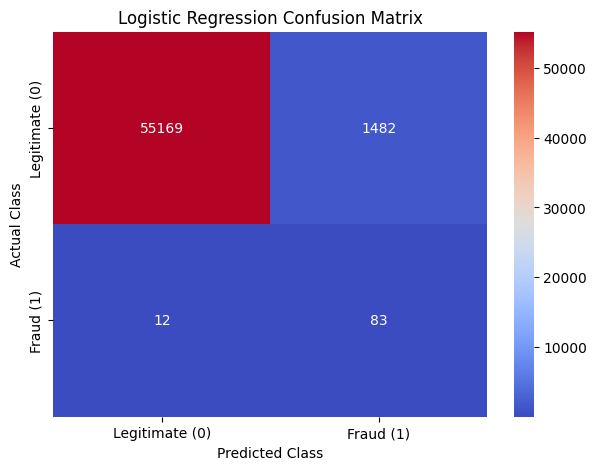

In [17]:
#Importing the required libraries from sklearn for Logistic Regression model evaluation
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score, matthews_corrcoef
from sklearn.metrics import confusion_matrix, classification_report

# Creating and Training the model for better performance
logistic_model = LogisticRegression(random_state=42, max_iter=1000)
logistic_model.fit(X_train_smote, Y_train_smote)

# Making predictions on the test data
Y_pred_logistic = logistic_model.predict(X_test)

# Getting the probability values for fraud transactions
Y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

# Checking the logistic model performance using different evaluation metrics
print("Performance of Logistic Regression:", "\n")
print("Accuracy:", accuracy_score(Y_test, Y_pred_logistic))
print("Precision:", precision_score(Y_test, Y_pred_logistic))
print("Recall:", recall_score(Y_test, Y_pred_logistic))
print("F1 Score:", f1_score(Y_test, Y_pred_logistic))
print("ROC-Area Under Curve:", roc_auc_score(Y_test, Y_prob_logistic))
print("Matthews Correlation Coefficient:", matthews_corrcoef(Y_test, Y_pred_logistic))

# Generating and Displaying the classification report each class
print("\nClassification Report:","\n",classification_report(Y_test, Y_pred_logistic))

# Creating the confusion matrix to check the results of the prediction values
confusion_mat = confusion_matrix(Y_test, Y_pred_logistic)
print("\nConfusion Matrix:","\n",confusion_mat)

# Plotting the confusion matrix of fraud and legitimate transactions
plt.figure(figsize=(7, 5))
sns.heatmap(confusion_mat, annot=True, fmt='d', cmap='coolwarm',xticklabels=['Legitimate (0)', 'Fraud (1)'],yticklabels=['Legitimate (0)', 'Fraud (1)'])
#assigning titles for the plotted confusion matrix
plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()

 **Performance of Logistic Regression Model**

Successfully trained the logistic Regression model using the SMOTE balanced training data. This model achieved 97.36% accuracy, 5.30% precision, 87.36% recall, 0.10 F1-score, 0.9619 ROC-AUC, and 0.2116 of Matthews Correlation Coefficient.

The confusion matrix shows that the model correctly found 55,169 legitimate transactions and 83 fraudulent transactions. It incorrectly classified 1,482 legitimate transactions as fraud and missed 12 fraudulent transactions.

The results show that the model was able to detect most fraudulent transactions, but the low precision shows a high number of false positives values.

Random Forest Model Performance

Accuracy: 0.9994713283755683
Precision: 0.9113924050632911
Recall: 0.7578947368421053
F1 Score: 0.8275862068965517
ROC-AUC: 0.9574483285936329
MCC: 0.830854576899801

Classification Report: 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.91      0.76      0.83        95

    accuracy                           1.00     56746
   macro avg       0.96      0.88      0.91     56746
weighted avg       1.00      1.00      1.00     56746


Confusion Matrix: 
 [[56644     7]
 [   23    72]]


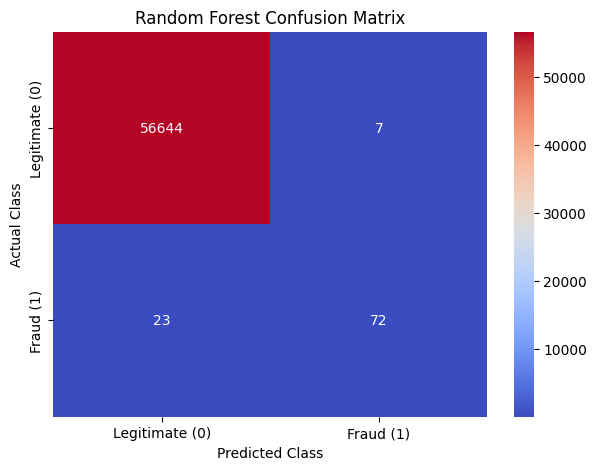

In [18]:
# Importing the required libraries from sklearn for Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score, matthews_corrcoef
from sklearn.metrics import confusion_matrix

# Creating and training the Random Forest classifier
random_forest_model = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
random_forest_model.fit(X_train_smote, Y_train_smote)

# Predicting the results using test data
Y_pred_rf = random_forest_model.predict(X_test)

# Getting the probability values for fraud transactions
Y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

# Evaluating the model performance by calculating different evaluation metrics
print("Random Forest Model Performance\n")
print("Accuracy:", accuracy_score(Y_test, Y_pred_rf))
print("Precision:", precision_score(Y_test, Y_pred_rf))
print("Recall:", recall_score(Y_test, Y_pred_rf))
print("F1 Score:", f1_score(Y_test, Y_pred_rf))
print("ROC-AUC:", roc_auc_score(Y_test, Y_prob_rf))
print("MCC:", matthews_corrcoef(Y_test, Y_pred_rf))

# Displaying the classification report for each class
print("\nClassification Report:","\n",classification_report(Y_test, Y_pred_rf))

# Creating the confusion matrix of fraudulent and legitimate transactions
confusion_rf = confusion_matrix(Y_test, Y_pred_rf)
print("\nConfusion Matrix:","\n",confusion_rf)

# Plotting the confusion matrix of Transactions and different classes
plt.figure(figsize=(7, 5))
sns.heatmap(confusion_rf, annot=True, fmt='d', cmap='coolwarm',xticklabels=['Legitimate (0)', 'Fraud (1)'],yticklabels=['Legitimate (0)', 'Fraud (1)'])
#assigning titles for the plotted confusion matrix graph of the transactions
plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()

**Performance of Random Forest Model**

Trained and evaluated the Random Forest model using the SMOTE balanced training data. This model achieved 99.95% accuracy, 91.14% precision, 75.79% recall, 0.8276 F1-score, 0.9574 ROC-AUC, and 0.8309 Matthews Correlation Coefficient.

The confusion matrix shows that the model correctly found 56,644 legitimate transactions and 72 fraudulent transactions. but it incorrectly classified 7 legitimate transactions as fraud and missed 23 fraudulent transactions.

The results of the Random Forest model gave a  high precision with very few false positives, but it missed some fraudulent transactions.

XGBoost Model Performance

Accuracy: 0.9958763613294329
Precision: 0.26755852842809363
Recall: 0.8421052631578947
F1 Score: 0.40609137055837563
ROC-AUC: 0.9750926494538583
MCC: 0.47334487808069114

Classification Report: 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.27      0.84      0.41        95

    accuracy                           1.00     56746
   macro avg       0.63      0.92      0.70     56746
weighted avg       1.00      1.00      1.00     56746


Confusion Matrix:
 [[56432   219]
 [   15    80]]


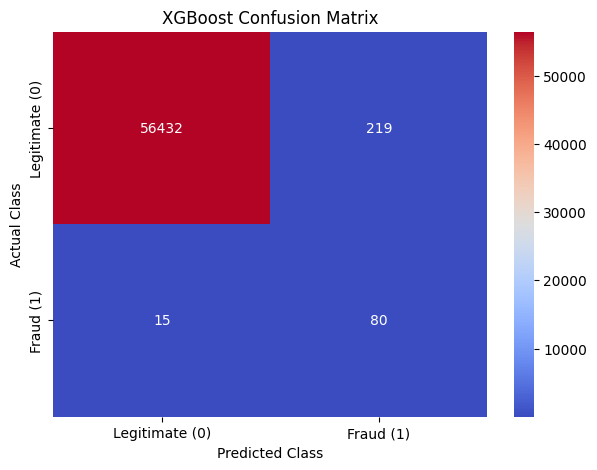

In [19]:
# Importing the required libraries from sklearn for XGBoost model
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score, matthews_corrcoef
from sklearn.metrics import confusion_matrix, classification_report

# Creating and training the XGBoost model
xgb_model = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5,random_state=42, eval_metric='logloss', n_jobs=-1)
xgb_model.fit(X_train_smote, Y_train_smote)

# Predicting the results using test data
Y_pred_xgb = xgb_model.predict(X_test)

# Getting the probability scores for fraud transactions
Y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Evaluating the model performance by calculating different evaluation metrics
print("XGBoost Model Performance\n")
print("Accuracy:", accuracy_score(Y_test, Y_pred_xgb))
print("Precision:", precision_score(Y_test, Y_pred_xgb))
print("Recall:", recall_score(Y_test, Y_pred_xgb))
print("F1 Score:", f1_score(Y_test, Y_pred_xgb))
print("ROC-AUC:", roc_auc_score(Y_test, Y_prob_xgb))
print("MCC:", matthews_corrcoef(Y_test, Y_pred_xgb))

# Displaying the classification report for each class
print("\nClassification Report:","\n",classification_report(Y_test, Y_pred_xgb))

# Creating the confusion matrix of Legitimate and Fraud Transactions
confusion_xgb = confusion_matrix(Y_test, Y_pred_xgb)
print("\nConfusion Matrix:\n", confusion_xgb)

# Plotting the confusion matrix of the transactions
plt.figure(figsize=(7, 5))
sns.heatmap(confusion_xgb, annot=True, fmt='d', cmap='coolwarm',xticklabels=['Legitimate (0)', 'Fraud (1)'],yticklabels=['Legitimate (0)', 'Fraud (1)'])
#assigning titles for the XGBoost Classifier
plt.title('XGBoost Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()

**Performance of XGBoost Model**

The XGBoost model got trained and evaluated using the SMOTE balanced training data. This model achieved 99.59% of accuracy, 26.76% precision, 84.21% recall, 0.4061 F1-score, 0.9751 ROC-AUC, and 0.4733 Matthews Correlation Coefficient.

The confusion matrix results shows that this model correctly identified 56,432 legitimate transactions and 80 fraudulent transactions. but it incorrectly classified 219 legitimate transactions as fraud and missed 15 fraudulent transactions.

The results show that XGBoost was able to identify most of the fraudulent transactions, with a recall of 84.21%. but the precision of 26.76% indicates that so many legitimate transactions were identified as fraud incorrectly.

Voting Classifier Model Performance

Accuracy: 0.9980791597645648
Precision: 0.45977011494252873
Recall: 0.8421052631578947
F1 Score: 0.5947955390334573
ROC-AUC: 0.9789319462006059
MCC: 0.6214411492334001

Classification Report: 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.46      0.84      0.59        95

    accuracy                           1.00     56746
   macro avg       0.73      0.92      0.80     56746
weighted avg       1.00      1.00      1.00     56746


Confusion Matrix:
 [[56557    94]
 [   15    80]]


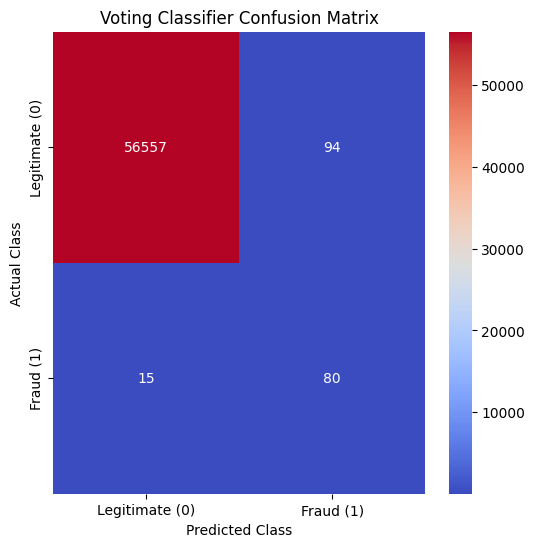

In [20]:
# Importing the required libraries from sklearn for Voting Classifier
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score, matthews_corrcoef
from sklearn.metrics import confusion_matrix, classification_report

# Creating the Voting Classifier using the previous three models
vote_model = VotingClassifier(estimators=[('lr', logistic_model),('rf', random_forest_model),('xgb', xgb_model) ],voting='soft',n_jobs=1)

# Training the Voting Classifier using the three models
vote_model.fit(X_train_smote, Y_train_smote)

# Predicting the  final results using tested data
Y_pred_voting = vote_model.predict(X_test)

# Getting the probability values for fraud transactions
Y_prob_voting = vote_model.predict_proba(X_test)[:, 1]

# Evaluating the model performance by using different evaluation metrics
print("Voting Classifier Model Performance\n")
print("Accuracy:", accuracy_score(Y_test, Y_pred_voting))
print("Precision:", precision_score(Y_test, Y_pred_voting))
print("Recall:", recall_score(Y_test, Y_pred_voting))
print("F1 Score:", f1_score(Y_test, Y_pred_voting))
print("ROC-AUC:", roc_auc_score(Y_test, Y_prob_voting))
print("MCC:", matthews_corrcoef(Y_test, Y_pred_voting))

# Evaluating model performance for each class
print("\nClassification Report:","\n",classification_report(Y_test, Y_pred_voting))

#Creating and printing the confusion matrix of Legitimate and Fraud Transactions
cm_vote = confusion_matrix(Y_test, Y_pred_voting)
print("\nConfusion Matrix:\n", cm_vote)

# Plotting the confusion matrix of Transactions
plt.figure(figsize=(6, 6))
sns.heatmap(cm_vote,annot=True,fmt='d',cmap='coolwarm',xticklabels=['Legitimate (0)', 'Fraud (1)'],yticklabels=['Legitimate (0)', 'Fraud (1)'])
#assigning titles for the confusion matrix graph
plt.title('Voting Classifier Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()

**Performance of Voting Classifier Model**

Successfully trained and evaluated the Voting Classifier using the SMOTE balanced training data. The model achieved 99.81% accuracy, 45.98% precision, 84.21% recall, 0.5948 F1-score, 0.9789 ROC-AUC, and 0.6214 Matthews Correlation Coefficient.

The confusion matrix shows that the model correctly identified 56,557 legitimate transactions and 80 fraudulent transactions. but it incorrectly classified 94 legitimate transactions as fraud and missed 15 fraudulent transactions.

The results show that this was able to identify most fraudulent transactions while reducing the number of false positives. With 84.21% recall and 45.98% precision, this model gives a better understanding of the  balance between detecting fraudulent transactions and correctly identifying legitimate transactions.